<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/Kopie_von_02_tasks_metrics_nn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Заняття 2. Типи ML-задач, бізнес-метрики успіху й огляд нейромереж

**Блок 1. ML-фундамент і бізнес-рамка**

## 1. Типи ML-задач

**Навчання з учителем** (supervised): в історичних даних є правильна відповідь `y`.

| Тип | Що прогнозуємо | Бізнес-приклади |
|---|---|---|
| **Регресія** | число | виручка завтра, ціна квартири, кількість звернень |
| **Класифікація** | категорію (часто «так/ні») | піде клієнт чи ні, поверне кредит чи ні, спам чи ні |
| **Прогноз часового ряду** | число в майбутньому за часом | продажі на 4 тижні вперед |

**Навчання без учителя** (unsupervised): правильної відповіді немає, шукаємо структуру.

| Тип | Що робить | Бізнес-приклади |
|---|---|---|
| **Кластеризація** | групує схожі об'єкти | сегменти клієнтів, типи магазинів |
| **Пошук аномалій** | знаходить нетипове | підозрілі транзакції, збої датчиків |

**Як визначити тип:** запитайте *«Що саме я хочу отримати для одного об'єкта?»*
Число → регресія. Категорія → класифікація. Групи без готових відповідей → кластеризація.

## 2. Метрики успіху: три рівні

Модель може бути «точною» і при цьому марною для бізнесу. Тому успіх міряємо на трьох рівнях:

| Рівень | Запитання | Приклад: модель відтоку клієнтів |
|---|---|---|
| **Бізнес-метрика** | що змінилось у грошах чи процесі? | зекономлена виручка, % відтоку |
| **ML-метрика** | наскільки добре модель прогнозує? | яку частку клієнтів, що підуть, модель знаходить |
| **Операційна** | чи можна нею користуватися? | прогноз щоранку о 8:00, пояснення для менеджера |

**Домовляйтеся про бізнес-метрику до моделювання.** Корисне формулювання:
*«Модель успішна, якщо кампанія утримання за її списком дасть більше прибутку, ніж розсилка навмання»*.

### Приклад розрахунку бізнес-ефекту

Сервіс підписки має 10 000 клієнтів, 15 % з них підуть цього місяця. Утримання одного клієнта —
знижка 100 грн; утриманий клієнт приносить 1 500 грн; знижка утримує 30 % тих, хто збирався піти.
Бюджет — 1 000 знижок. Порівняємо: роздати навмання чи за списком моделі.

In [1]:
# =====================================================================
# КРОК 1. Оголошуємо функцію для розрахунку фінансового результату акції
# =====================================================================
def campaign_profit(
    contacted,          # Скільком клієнтам ми загалом надіслали пропозицію зі знижкою
    churners_found,     # Скільки з цих клієнтів реально збиралися піти від нас
    discount=100,       # Розмір знижки для одного клієнта (грн), за замовчуванням 100
    client_value=1500,  # Скільки грошей принесе компанії втриманий клієнт (грн)
    save_rate=0.3       # Частка клієнтів, яких знижка реально переконає залишитись (30%)
):
    """
    Рахує чистий прибуток маркетингової кампанії з утримання клієнтів.
    Формула: (Дохід від врятованих клієнтів) - (Витрати на всі роздані знижки)
    """
    # 1. Рахуємо, скільки клієнтів вдалося реально врятувати.
    # Знижка діє лише на тих, хто хотів піти (churners_found), і лише з ймовірністю 30% (save_rate).
    # Ті, хто не збирався йти, просто візьмуть знижку, але нового прибутку не принесуть.
    saved_clients = churners_found * save_rate

    # 2. Рахуємо гроші (виручку), які принесуть компанії врятовані клієнти
    revenue = saved_clients * client_value

    # 3. Рахуємо витрати на проведення кампанії.
    # Знижку отримують УСІ клієнти, яким ми її запропонували (contacted), незалежно від їхніх намірів.
    total_cost = contacted * discount

    # 4. Рахуємо чистий прибуток (або збиток, якщо число вийде з мінусом)
    net_profit = revenue - total_cost

    return net_profit


# =====================================================================
# КРОК 2. Задаємо вхідні бізнес-умови задачі
# =====================================================================
budget_contacts = 1000   # Наш бюджет дозволяє видати рівно 1 000 знижок
base_churn_rate = 0.15   # За статистикою минулих місяців, від нас іде 15% клієнтів
model_precision = 0.45   # Точність моделі: серед 1 000 обраних нею людей 45% реально підуть


# =====================================================================
# КРОК 3. Порівнюємо два підходи: «Навмання» проти «Роботи моделі»
# =====================================================================

# Варіант А: Беремо 1 000 випадкових клієнтів з бази (без моделі).
# Оскільки по всій базі йдуть 15%, серед випадкової тисячі таких буде 150 осіб.
churners_random = budget_contacts * base_churn_rate
random_pick = campaign_profit(
    contacted=budget_contacts,
    churners_found=churners_random
)

# Варіант Б: Модель проаналізувала базу і відібрала 1 000 найризиковіших клієнтів.
# Серед них частка реальних «втікачів» вища втричі (45%), тобто 450 осіб.
churners_model = budget_contacts * model_precision
model_pick = campaign_profit(
    contacted=budget_contacts,
    churners_found=churners_model
)


# =====================================================================
# КРОК 4. Виводимо результати та рахуємо вигоду від впровадження моделі
# =====================================================================

print(f"Результат роздачі знижок навмання: {random_pick:,.0f} грн") # Формат :,.0f означає: розділяти тисячі комою (102,500) і не показувати копійки (.0f)
print(f"Результат роботи за списком моделі: {model_pick:,.0f} грн")

# Додатково показуємо фінансову цінність самої ML-моделі
ml_business_value = model_pick - random_pick
print(f"Чиста фінансова вигода від моделі:   +{ml_business_value:,.0f} грн")


Результат роздачі знижок навмання: -32,500 грн
Результат роботи за списком моделі: 102,500 грн
Чиста фінансова вигода від моделі:   +135,000 грн


Навмання кампанія **збиткова**, а зі списком моделі — прибуткова. Саме це число (а не «точність
87 %») переконує бізнес. ML-метрику, що стоїть за цим прикладом (частка тих, хто піде, серед
обраних моделлю).

## 3. Демонстрація: сегментація клієнтів (кластеризація)

Мережа магазинів хоче розробити різні пропозиції для різних груп клієнтів. Готових груп немає —
шукаємо їх у даних методом **K-Means**: алгоритм розкладає клієнтів на `k` груп так, щоб
усередині групи клієнти були схожі.

In [2]:
# Підготовка: бібліотеки та функція завантаження даних (працює в Colab і локально)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data/"


def load_csv(name):
    """Читає CSV з поточної теки, з теки data/, з DATA_URL або просить завантажити файл у Colab."""
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)
    if DATA_URL:
        return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)
    from google.colab import files
    print(f"Натисніть «Choose files» і виберіть файл {name}")
    files.upload()
    return pd.read_csv(name)

In [ ]:
customers = load_csv("store_customers.csv")
customers.head()

,customer_id,visits_per_year,avg_check_uah,days_since_last_purchase,online_share,discount_share,annual_spend_uah
0,C10000,83,709.0,5,0.25,0.24,58847.0
1,C10001,9,4964.0,31,0.65,0.08,44676.0
2,C10002,7,5287.0,32,0.78,0.00,37009.0
3,C10003,4,629.0,236,0.22,0.46,2516.0
4,C10004,27,478.0,32,0.25,0.43,12906.0


**Важливо:** K-Means міряє «відстань» між клієнтами. Якщо одна ознака в гривнях (тисячі), а інша —
частка від 0 до 1, гривні «переважать» усе. Тому спочатку **масштабуємо** ознаки
(`StandardScaler` приводить кожну до середнього 0 і розкиду 1).

,customer_id,visits_per_year,avg_check_uah,days_since_last_purchase,online_share,discount_share,annual_spend_uah
0,C10000,83,709.0,5,0.25,0.24,58847.0
1,C10001,9,4964.0,31,0.65,0.08,44676.0
2,C10002,7,5287.0,32,0.78,0.00,37009.0
3,C10003,4,629.0,236,0.22,0.46,2516.0
4,C10004,27,478.0,32,0.25,0.43,12906.0


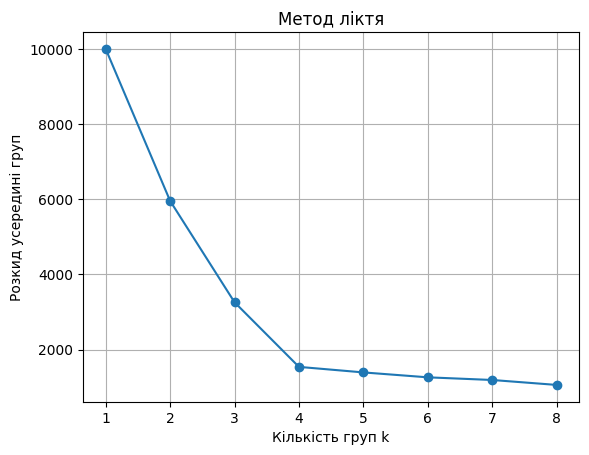

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data/"

def load_csv(name):
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)

    return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)

# Завантажуємо дані клієнтів
customers = load_csv("store_customers.csv")

# Перевіряємо, чи завантажилися дані
display(customers.head())

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

seg_features = [
    "visits_per_year",
    "avg_check_uah",
    "days_since_last_purchase",
    "online_share",
    "discount_share",
]

# Масштабуємо ознаки
X_scaled = StandardScaler().fit_transform(
    customers[seg_features]
)

# Метод ліктя
inertia = [
    KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    ).fit(X_scaled).inertia_
    for k in range(1, 9)
]

# Будуємо графік
plt.plot(range(1, 9), inertia, marker="o")
plt.xlabel("Кількість груп k")
plt.ylabel("Розкид усередині груп")
plt.title("Метод ліктя")
plt.xticks(range(1, 9))
plt.grid()
plt.show()

Після `k = 4` крива майже не падає — додаткові групи вже мало що пояснюють. Беремо 4 сегменти.

In [5]:
# 1. Ініціалізуємо модель KMeans із 4 кластерами (оптимальна кількість, визначена за методом ліктя).
# Параметри n_init=10 та random_state=42 забезпечують стабільний і відтворюваний результат.
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)

# 2. Навчаємо модель на масштабованих даних (X_scaled) та одразу присвоюємо кожному клієнту номер його групи (від 0 до 3).
# Результат записуємо в новий стовпець "segment" основної таблиці customers.
customers["segment"] = kmeans.fit_predict(X_scaled)

# 3. Створюємо зведену таблицю профілів для аналізу сегментів.
# Групуємо клієнтів за номером сегмента, рахуємо середні значення (mean) для обраних ознак і річних витрат,
# а потім округлюємо числа до одного знака після коми (round(1)).
profile = (
    customers.groupby("segment")[seg_features + ["annual_spend_uah"]]
    .mean()
    .round(1)
)

# 4. Додаємо до таблиці профілів стовпець "clients" із кількістю клієнтів у кожному сегменті.
# Метод sort_index() впорядковує підрахунок за номерами сегментів (0, 1, 2, 3), щоб вони точно збігалися з рядками таблиці.
profile["clients"] = customers["segment"].value_counts().sort_index()

profile

,visits_per_year,avg_check_uah,days_since_last_purchase,online_share,discount_share,annual_spend_uah,clients
segment,,,,,,,
0,60.2,644.7,6.0,0.4,0.2,38953.3,499
1,5.1,499.1,224.8,0.3,0.4,2514.9,479
2,6.1,4172.4,45.2,0.7,0.1,25318.7,300
3,23.9,355.3,21.9,0.2,0.5,8405.1,722


**Найважливіше в кластеризації робить аналітик**: дає сегментам назви й пропонує дії. Прочитайте
таблицю профілів і знайдіть, наприклад:
- часті візити, середній чек, свіжі покупки → **«постійні»** — програма лояльності;
- рідкісні візити, дуже великий чек, переважно онлайн → **«великі онлайн-покупки»** — персональні пропозиції;
- давно не купували → **«сплячі»** — кампанія повернення;
- багато покупок зі знижкою → **«мисливці за знижками»** — акції.

Номери сегментів (0, 1, 2, 3) випадкові — назви даємо, дивлячись на профіль.

## 4. Огляд: що таке нейромережа

**Нейрон** — це зважена сума ознак, пропущена через просту нелінійну функцію.
**Нейромережа** — багато нейронів у кількох шарах: вихід одного шару — вхід наступного.
Завдяки шарам мережа може знаходити дуже складні закономірності.

| Нейромережі сильні | Нейромережі слабкі |
|---|---|
| зображення, текст, звук, відео | невеликі таблиці (тисячі рядків) |
| мільйони прикладів | коли треба пояснити рішення бізнесу |
| готові моделі (ChatGPT, розпізнавання облич) | мало часу й обчислювальних ресурсів |

**Для аналітика на табличних бізнес-даних** зазвичай краще працюють простіші моделі (регресії,
дерева, бустинг). Але знати ідею треба: нейромережі всюди навколо, а `scikit-learn`
має невелику мережу `MLPClassifier`, яка працює на звичайному ноутбуці.

### Демонстрація: розпізнавання рукописних цифр

Кожна картинка — 8×8 пікселів, тобто 64 ознаки (яскравість пікселя). Ціль — цифра від 0 до 9.

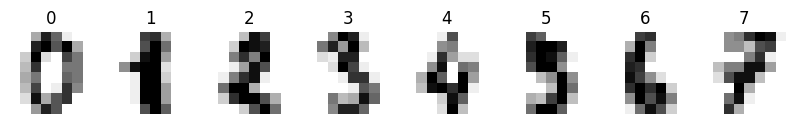

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

# Завантажуємо вбудований датасет із зображеннями рукописних цифр (від 0 до 9)
digits = load_digits()

# Створюємо полотно (fig) та сітку з 8 комірок для графіків в 1 рядок (розмір 10 на 1.6 дюйма)
fig, axes = plt.subplots(1, 8, figsize=(10, 1.6))

# Одночасно перебираємо перші 8 комірок, перші 8 матриць картинок та перші 8 правильних відповідей
for ax, img, label in zip(axes, digits.images, digits.target):
    # Відображаємо матрицю 8x8 як чорно-білу картинку (gray_r: білий фон, темна цифра)
    ax.imshow(img, cmap="gray_r")
    # Додаємо заголовок над картинкою з правильною цифрою
    ax.set_title(label)
    # Вимикаємо відображення координатних осей та поділок навколо картинки
    ax.axis("off")

# Виводимо сформований ряд із 8 картинок на екран
plt.show()

# Розділяємо дані на навчальну (75%) та тестову (25%) вибірки
X_tr, X_te, y_tr, y_te = train_test_split(
    digits.data,              # Вхідні ознаки (1797 картинок, розтягнутих у рядки по 64 пікселі)
    digits.target,            # Правильні відповіді (цифри від 0 до 9 для кожної картинки)
    test_size=0.25,           # Відкладаємо 25% даних для перевірки (тесту), 75% піде на навчання
    random_state=42,          # Фіксуємо випадковість, щоб поділ був однаковим при кожному запуску
    stratify=digits.target    # Зберігаємо однакову пропорцію кожної цифри (0..9) в обох вибірках
)


In [7]:
# Нейромережа з одним прихованим шаром на 64 нейрони

# Створюємо багатошаровий перцептрон (нейромережу) з 1 прихованим шаром на 64 нейрони,
# лімітом у 1000 циклів навчання (епох) та фіксованою випадковістю
mlp = MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=42)  # Multi-Layer Perceptron Classifier — багатошаровий перцептрон для класифікації

# Навчаємо нейромережу на тренувальних даних, попередньо поділивши пікселі на 16
# (щоб яскравість була від 0 до 1 — нейромережі працюють краще з такими числами)
mlp.fit(X_tr / 16, y_tr)

# Перевіряємо точність (Accuracy) нейромережі на тестових даних (також масштабованих на 16)
acc_mlp = mlp.score(X_te / 16, y_te)


# Створюємо простішу лінійну модель (логістичну регресію) для порівняння з нейромережею,
# встановлюємо ліміт у 2000 кроків для пошуку оптимальних ваг
logreg = LogisticRegression(max_iter=2000)

# Навчаємо логістичну регресію на тих самих відмасштабованих тренувальних даних
logreg.fit(X_tr / 16, y_tr)

# Перевіряємо точність (Accuracy) логістичної регресії на тих самих тестових даних
acc_lr = logreg.score(X_te / 16, y_te)


print(f"Нейромережа: правильно розпізнано {acc_mlp:.1%} цифр")
print(f"Логістична регресія: правильно розпізнано {acc_lr:.1%} цифр")

Нейромережа: правильно розпізнано 98.2% цифр
Логістична регресія: правильно розпізнано 96.2% цифр


Обидві моделі розпізнають цифри дуже добре, нейромережа — трохи краще. На картинках це типово:
сусідні пікселі пов'язані між собою, і шари мережі вловлюють ці зв'язки. На табличних бізнес-даних
ви побачите іншу картину.

---
## 5. Практика

### Завдання 1. Від бізнес-питання до ML-задачі

Для кожної ситуації заповніть: тип задачі, ціль `y` (або «немає»), ML-метрику (словами),
бізнес-метрику.

1. Інтернет-магазин хоче знати, скільки замовлень надійде наступного тижня
2. Банк хоче знати, які заявки на кредит, імовірно, не повернуть
3. Мережа фітнес-клубів хоче зрозуміти, які типи відвідувачів у неї є
4. HR хоче знати, хто з працівників, імовірно, звільниться найближчі пів року
5. Агенція нерухомості хоче автоматично оцінювати ціну оренди квартири

1. Інтернет-магазин хоче знати, скільки замовлень надійде наступного тижня.
- Тип задачі: прогнозування часового ряду.
- Ціль y: кількість замовлень за наступний тиждень.
- ML-метрика: MAE — середня абсолютна помилка прогнозу кількості замовлень.
- Бізнес-метрика: зменшення витрат на зберігання товарів, оптимізація запасів і своєчасне виконання замовлень.
2. Банк хоче знати, які заявки на кредит, імовірно, не повернуть.
- Тип задачі: класифікація.
- Ціль y: поверне кредит чи ні (1 — дефолт, 0 — кредит повернуто).
- ML-метрика: Precision і Recall — наскільки добре модель знаходить клієнтів, які можуть не повернути кредит.
- Бізнес-метрика: зменшення фінансових втрат від неповернутих кредитів.
3. Мережа фітнес-клубів хоче зрозуміти, які типи відвідувачів у неї є.
- Тип задачі: кластеризація.
- Ціль y: немає, оскільки готових категорій клієнтів немає.
- ML-метрика: Silhouette Score — показує, наскільки добре клієнти розподілені на окремі групи.
- Бізнес-метрика: збільшення утримання клієнтів, продажів абонементів і ефективності персональних пропозицій.
4. HR хоче знати, хто з працівників, імовірно, звільниться найближчі пів року.
- Тип задачі: класифікація.
- Ціль y: звільниться чи залишиться (1 — звільниться, 0 — залишиться).
- ML-метрика: Recall і Precision — наскільки добре модель знаходить працівників, які можуть звільнитися.
- Бізнес-метрика: зменшення витрат на пошук і найм нових працівників, зниження плинності кадрів.
5. Агенція нерухомості хоче автоматично оцінювати ціну оренди квартири.
- Тип задачі: регресія.
- Ціль y: ціна оренди квартири (грн або євро на місяць).
- ML-метрика: MAE і RMSE — показують середню помилку прогнозування вартості оренди.
- Бізнес-метрика: точніше ціноутворення, швидший продаж або здача нерухомості в оренду, збільшення доходу агенції.

Тип ML-задачі залежить від того, який результат потрібно отримати. Якщо прогнозуємо число — це регресія або прогнозування часового ряду; якщо визначаємо категорію — класифікація; якщо шукаємо групи без готових відповідей — кластеризація. Успіх кожної моделі потрібно оцінювати не лише за ML-метриками, а й за її реальним впливом на бізнес.

### Завдання 2. Порахуйте бізнес-ефект

Банк перевіряє 2 000 заявок; 10 % з них — майбутні дефолти. Один дефолт коштує банку 40 000 грн,
а відхилена хороша заявка — 6 000 грн втраченого прибутку. Модель відхиляє 300 заявок, серед них
150 — справжні майбутні дефолти.

1. Скільки грошей банк зберіг на дефолтах, яких уникнув?
2. Скільки втратив на хороших заявках, які відхилив помилково?
3. Який чистий ефект моделі? Чи варто її використовувати?

In [8]:
# Ефект позитивний: модель варто використовувати, але варто перевірити інші пороги відхилення.
defaults_avoided = 150
good_rejected = 300 - defaults_avoided
saved = defaults_avoided * 40000
lost = good_rejected * 6000
print(f'{saved:,}, {lost}, {saved - lost}')

6,000,000, 900000, 5100000


### Завдання 3. Сегментація вин

Постачальник має 178 вин з хімічним аналізом (набір `load_wine` з `scikit-learn`) і хоче
розкласти їх на лінійки для каталогу.

1. Завантажте дані: `from sklearn.datasets import load_wine`, `wine = load_wine(as_frame=True)`,
   ознаки — `wine.data`.
2. Масштабуйте ознаки й побудуйте графік методу ліктя для `k` від 1 до 8.
3. Розбийте вина на 3 кластери й покажіть середні значення 4–5 ознак за кластерами.
4. Насправді вина походять з трьох сортів винограду (`wine.target`). Порівняйте кластери з сортами
   через `pd.crosstab`. Чи знайшов алгоритм справжні групи, не знаючи відповідей?

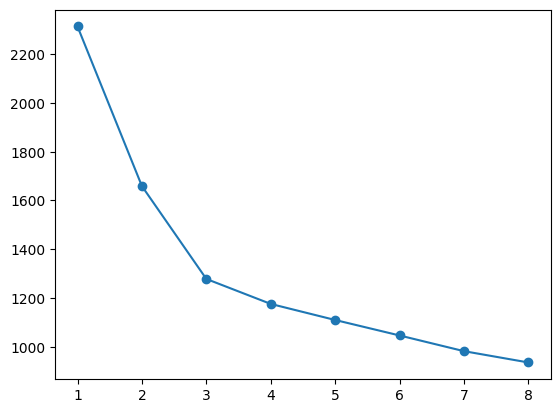

In [9]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)
X_w = StandardScaler().fit_transform(wine.data)
inertia_w = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_w).inertia_ for k in range(1,9)]
plt.plot(range(1,9), inertia_w, marker='o')



### Завдання 4. Нейромережа на таблиці

Навчіть на винах (ціль — сорт `wine.target`) дві моделі: `LogisticRegression(max_iter=2000)`
і `MLPClassifier(hidden_layer_sizes=(32,), max_iter=2000, random_state=42)`.

1. Розділіть дані `train_test_split(..., test_size=0.3, random_state=42, stratify=y)`.
2. Масштабуйте ознаки: `StandardScaler` навчайте (`fit`) лише на навчальних даних.
3. Порівняйте частку правильних відповідей (`.score`). Чи виграла нейромережа? Чому так може бути
   на маленькій таблиці?

In [10]:
# На малій таблиці проста модель працює не гірше: нейромережі потрібно багато даних,
# а тут зв'язки прості. Складніша модель не означає кращу.
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# 1. Завантажуємо дані
wine = load_wine()
X = wine.data
y = wine.target

# 2. Розділяємо дані на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 3. Масштабуємо ознаки
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Навчаємо Logistic Regression
log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train_scaled, y_train)

# 5. Навчаємо нейромережу
mlp = MLPClassifier(
    hidden_layer_sizes=(32,),
    max_iter=2000,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)

# 6. Порівнюємо точність моделей
log_reg_score = log_reg.score(X_test_scaled, y_test)
mlp_score = mlp.score(X_test_scaled, y_test)

print(f"Logistic Regression: {log_reg_score:.3f}")
print(f"Нейромережа (MLP):   {mlp_score:.3f}")

if mlp_score > log_reg_score:
    print("Нейромережа показала кращий результат.")
elif mlp_score < log_reg_score:
    print("Logistic Regression показала кращий результат.")
else:
    print("Обидві моделі показали однаковий результат.")

Logistic Regression: 0.981
Нейромережа (MLP):   0.981
Обидві моделі показали однаковий результат.


---
## Підсумок

- Тип задачі визначає відповідь на запитання *«що я хочу отримати для одного об'єкта?»*.
- Успіх моделі міряємо на трьох рівнях; **бізнес-метрику погоджуємо до моделювання**.
- Кластеризація знаходить групи без готових відповідей, але сенс групам дає аналітик.
- Нейромережі сильні на зображеннях і текстах; на невеликих таблицях прості моделі часто не гірші.